# OpenCV Crash Course: 2026 Edition
## Module 1: Introduction & Image Basics
**Estimated time: 30-40 minutes**

---

### What you'll learn
- Install & import OpenCV
- Read, display, and save images
- Image properties: shape, channels, dtype
- Color spaces: BGR, RGB, Grayscale, HSV
- Transformations: resize, crop, flip, rotate

> **Key fact:** OpenCV stores images as NumPy arrays in **BGR** order (not RGB). Always remember this!

In [1]:
# Run once to install
!pip install opencv-python opencv-contrib-python matplotlib numpy

  Using cached numpy-2.4.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached contourpy-1.3.3-cp312-cp312-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.62.1-cp312-cp312-win_amd64.whl.metadata (119 kB)
  Using cached kiwisolver-1.5.0-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.2.0-cp312-cp312-win_amd64.whl.metadata (9.0 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   --- ------------------------------------ 3.9/40.2 MB 19.5 MB/s eta 0:00:02
   ------ --------------------------------- 6.6/40.2 MB 16.1 MB/s eta 0:00:03
   --------- ------------------------------ 9.4/40.2 MB 14.7 MB/s eta 0:00:03
   ----------- ---------------------------- 12.1/40.2 MB 14.2 MB/s eta 0:00:02
   -------------- ------------------------- 14.7/40.2 MB 14.0 MB/s eta 0:00:02
   ----------------- ----------------


[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(f"OpenCV version: {cv2.__version__}")

# ------------------------------------------------------------------
# show()      - display a single image inline
# show_grid() - display multiple images side by side
# Copy these into every notebook you use in this course.
# ------------------------------------------------------------------
def show(img, title="", figsize=(7, 5)):
    plt.figure(figsize=figsize)
    if len(img.shape) == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap='gray')
    plt.title(title, fontsize=13)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

def show_grid(images, titles, cols=3, figsize=(15, 5)):
    rows = (len(images) - 1) // cols + 1
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.array(axes).flatten()
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 3:
            axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            axes[i].imshow(img, cmap='gray')
        axes[i].set_title(title, fontsize=11)
        axes[i].axis('off')
    for j in range(len(images), len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()

OpenCV version: 4.13.0


## 1. Reading & Displaying Images

OpenCV can read **JPG, PNG, BMP, TIFF** and more.  
Since we may not have a file handy, we'll **create a synthetic image** first using NumPy - this is a common technique in OpenCV workflows.

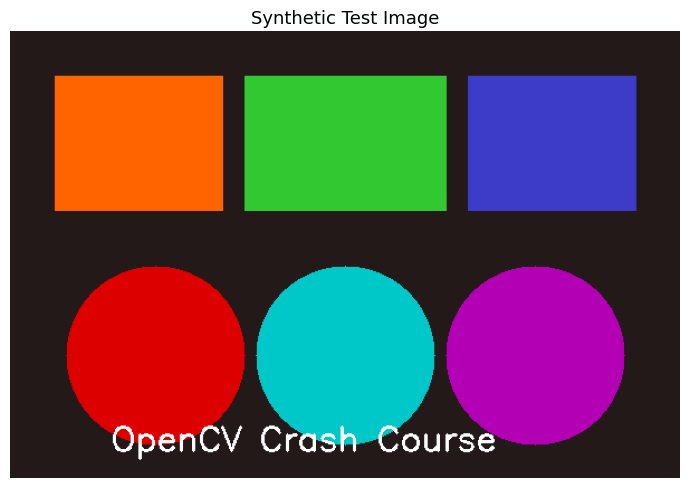

In [3]:
# ------ Create a colorful synthetic image (no external file needed) ------
canvas = np.zeros((400, 600, 3), dtype=np.uint8)
canvas[:] = (25, 25, 35)  # dark background (BGR)

# Colored rectangles
cv2.rectangle(canvas, (40,  40), (190, 160), (0,  100, 255), -1)   # orange
cv2.rectangle(canvas, (210, 40), (390, 160), (50, 200,  50), -1)   # green
cv2.rectangle(canvas, (410, 40), (560, 160), (200, 60,  60), -1)   # blue

# Colored circles
cv2.circle(canvas, (130, 290), 80, (0,   0, 220), -1)   # red
cv2.circle(canvas, (300, 290), 80, (200, 200,  0), -1)  # cyan
cv2.circle(canvas, (470, 290), 80, (180,  0, 180), -1)  # purple

cv2.putText(canvas, "OpenCV Crash Course",
            (90, 375), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)

show(canvas, "Synthetic Test Image")

Saved: test_image.jpg
Loaded image shape: (400, 600, 3)


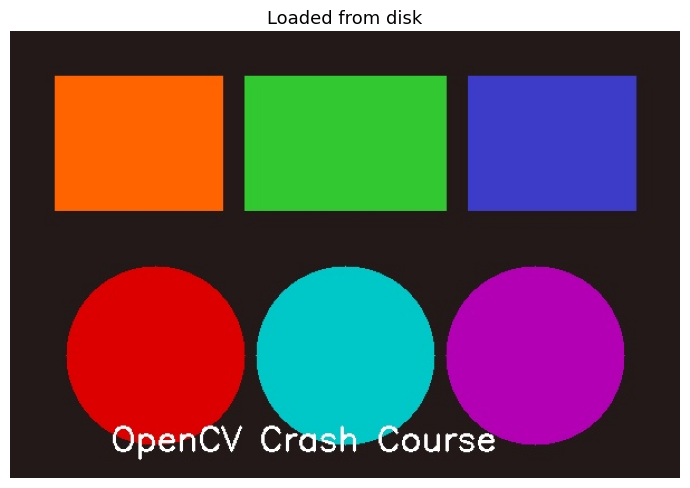

In [4]:
# ------ Save & reload (the real workflow) ------
import os
os.makedirs('input', exist_ok=True)
os.makedirs('output', exist_ok=True)

cv2.imwrite('input/test_image.jpg', canvas)
print("Saved: input/test_image.jpg")

# cv2.IMREAD_COLOR    -> BGR (default)
# cv2.IMREAD_GRAYSCALE -> single channel
# cv2.IMREAD_UNCHANGED -> keep alpha channel if present
img = cv2.imread('input/test_image.jpg', cv2.IMREAD_COLOR)

if img is None:
    print("File not found - check the path")
else:
    print(f"Loaded image shape: {img.shape}")
    show(img, "Loaded from disk")

In [5]:
# ------ Load your own image ------
# img = cv2.imread('input/your_photo.jpg')
# show(img, 'My Photo')

# For the rest of this notebook we use the synthetic canvas
img = canvas.copy()

## 2. Image Properties

Every OpenCV image is a **NumPy ndarray**. Knowing its shape is essential.

In [6]:
print(f"Shape      : {img.shape}")          # (height, width, channels)
print(f"Height     : {img.shape[0]} px")
print(f"Width      : {img.shape[1]} px")
print(f"Channels   : {img.shape[2]}")       # 3 = BGR, 1 = grayscale
print(f"Data type  : {img.dtype}")          # uint8 means 0-255 per channel
print(f"Total pixels: {img.shape[0] * img.shape[1]:,}")
print(f"Memory (bytes): {img.nbytes:,}")

# Access individual pixels - returns [B, G, R]
pixel = img[200, 130]  # row=200, col=130
print(f"\nPixel at (200,130): B={pixel[0]}, G={pixel[1]}, R={pixel[2]}")

Shape      : (400, 600, 3)
Height     : 400 px
Width      : 600 px
Channels   : 3
Data type  : uint8
Total pixels: 240,000
Memory (bytes): 720,000

Pixel at (200,130): B=25, G=25, R=35


## 3. Color Spaces

| Space | Use case |
|-------|----------|
| BGR   | Default OpenCV format |
| RGB   | What matplotlib / humans expect |
| Grayscale | Processing, thresholding, edges |
| HSV   | Color-based detection & filtering |

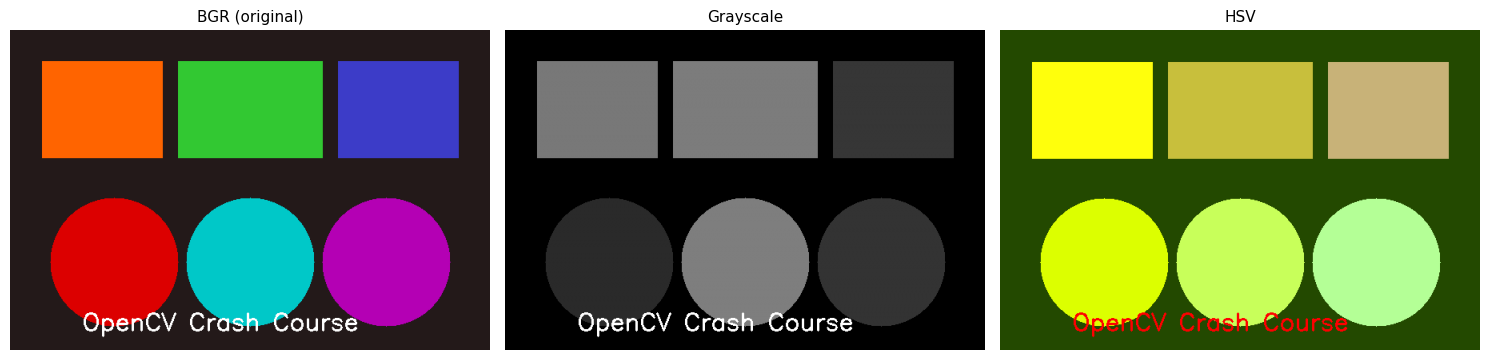

In [7]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv  = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

show_grid(
    [img, gray, hsv],
    ["BGR (original)", "Grayscale", "HSV"],
    cols=3
)

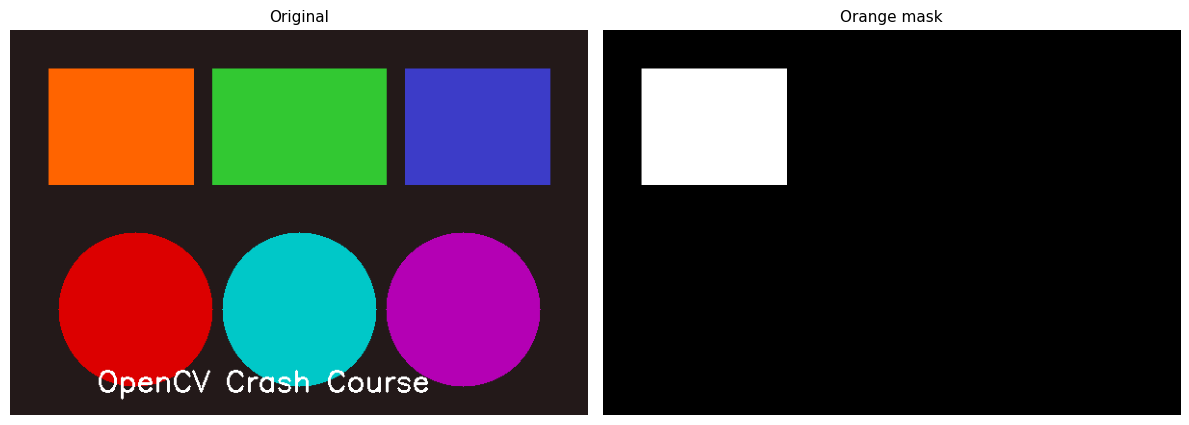

In [9]:
# HSV ranges in OpenCV
# H: 0-179  (hue - color wheel, half of 360)
# S: 0-255  (saturation - how vivid)
# V: 0-255  (value / brightness)

# Detect orange pixels using HSV range
lower_orange = np.array([5,  100, 100])
upper_orange = np.array([25, 255, 255])
mask = cv2.inRange(hsv, lower_orange, upper_orange)

show_grid([img, mask], ["Original", "Orange mask"], cols=2, figsize=(12, 5))

## 4. Basic Transformations

In [10]:
# ------ Resize ------
# Fixed size
img_300x200 = cv2.resize(img, (300, 200))  # (width, height)

# Scale factor (keep aspect ratio)
img_half = cv2.resize(img, None, fx=0.5, fy=0.5)
img_2x   = cv2.resize(img, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)

print(f"Original : {img.shape[:2]}")
print(f"Fixed    : {img_300x200.shape[:2]}")
print(f"Half     : {img_half.shape[:2]}")
print(f"Double   : {img_2x.shape[:2]}")

# Interpolation methods:
# cv2.INTER_LINEAR  - default, good for enlarging
# cv2.INTER_CUBIC   - better quality, slower
# cv2.INTER_AREA    - best for shrinking

Original : (400, 600)
Fixed    : (200, 300)
Half     : (200, 300)
Double   : (800, 1200)


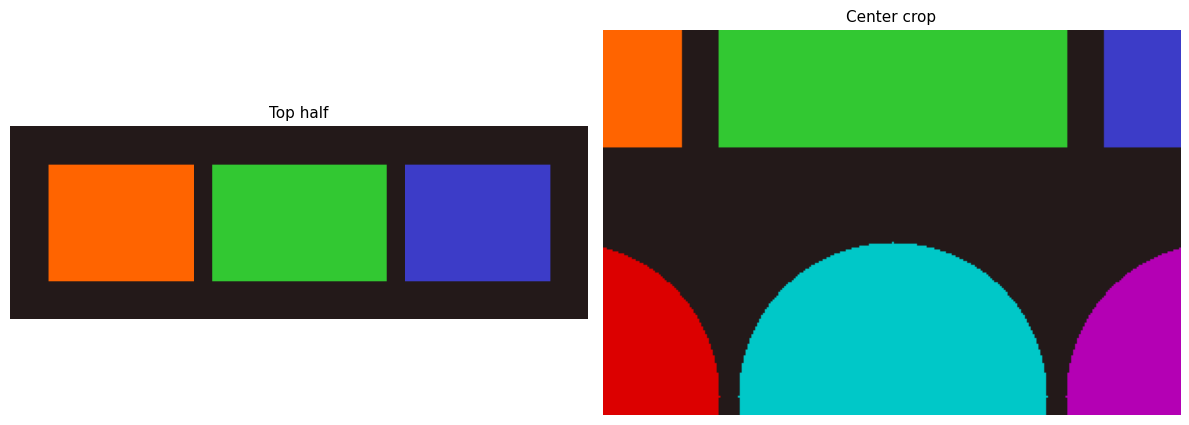

In [11]:
# ------ Crop ------
# Numpy slicing: img[y1:y2, x1:x2]
h, w = img.shape[:2]

top_half    = img[:h//2, :]           # top 50%
center_crop = img[100:300, 150:450]   # specific region

show_grid([top_half, center_crop], ["Top half", "Center crop"], cols=2, figsize=(12, 5))

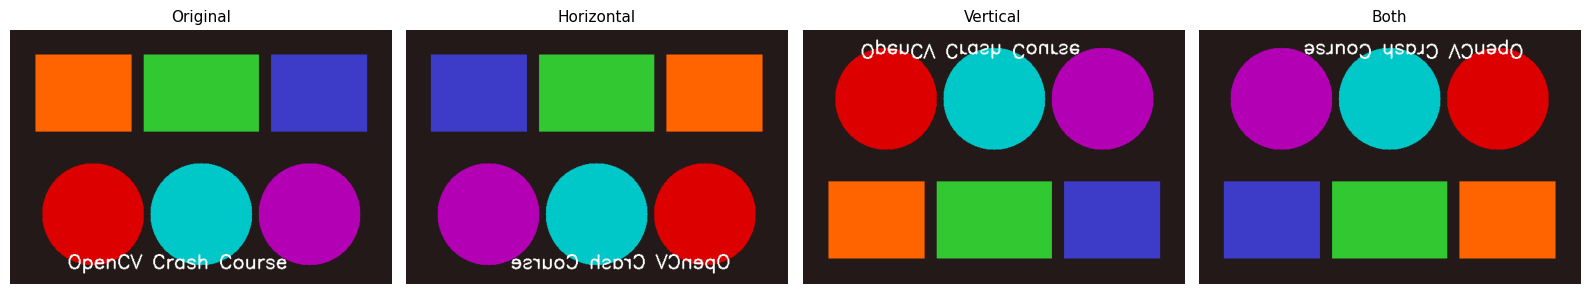

In [12]:
# ------ Flip ------
flip_h = cv2.flip(img,  1)   # flipCode  1 = horizontal (mirror)
flip_v = cv2.flip(img,  0)   # flipCode  0 = vertical
flip_b = cv2.flip(img, -1)   # flipCode -1 = both

show_grid(
    [img, flip_h, flip_v, flip_b],
    ["Original", "Horizontal", "Vertical", "Both"],
    cols=4, figsize=(16, 4)
)

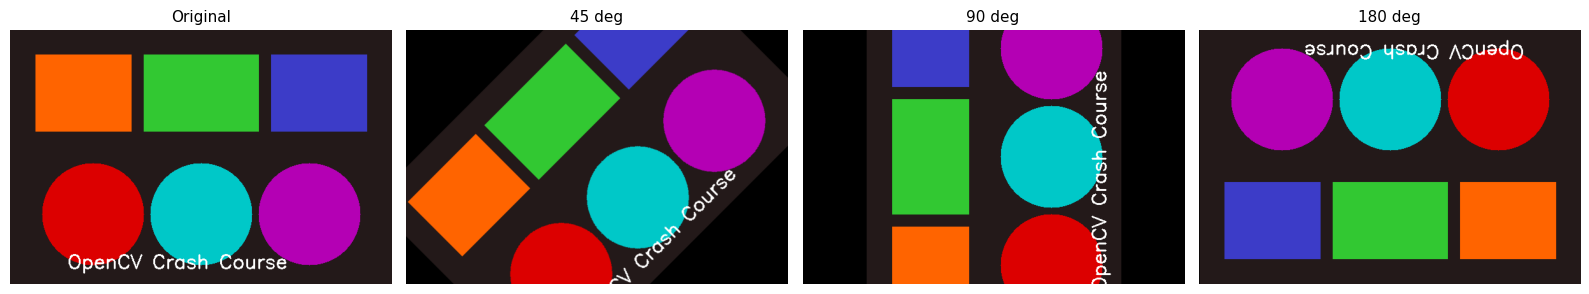

In [13]:
# ------ Rotate ------
h, w = img.shape[:2]
center = (w // 2, h // 2)

def rotate(image, angle, scale=1.0):
    M = cv2.getRotationMatrix2D(center, angle, scale)
    return cv2.warpAffine(image, M, (w, h))

r45  = rotate(img, 45)
r90  = rotate(img, 90)
r180 = rotate(img, 180)

show_grid(
    [img, r45, r90, r180],
    ["Original", "45 deg", "90 deg", "180 deg"],
    cols=4, figsize=(16, 4)
)

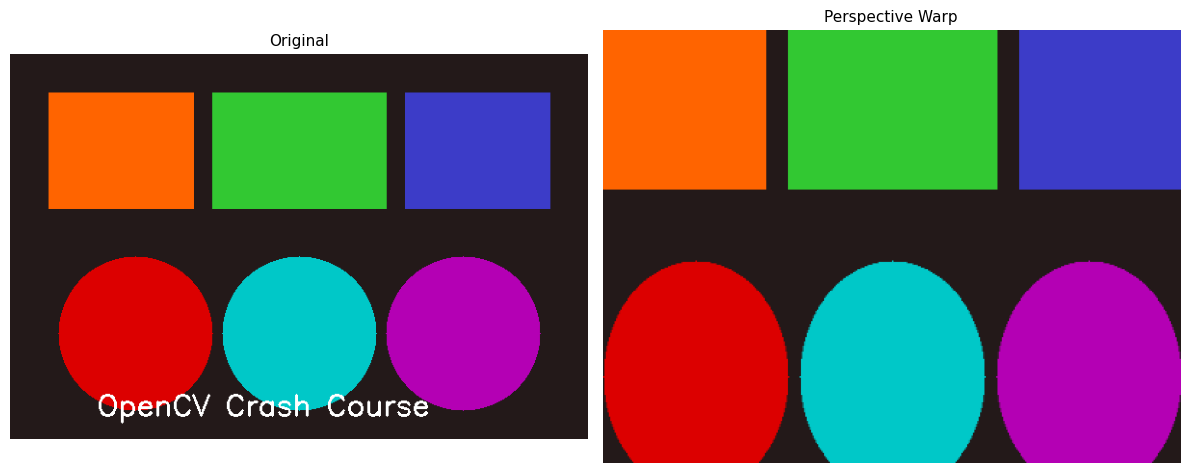

In [14]:
# ------ Perspective / Warp Transform ------
# Useful to straighten skewed documents or receipts
src_pts = np.float32([[50, 50], [550, 50], [50, 350], [550, 350]])
dst_pts = np.float32([[0,  0],  [400, 0],  [0,  300], [400, 300]])

M_persp = cv2.getPerspectiveTransform(src_pts, dst_pts)
warped  = cv2.warpPerspective(img, M_persp, (400, 300))

show_grid([img, warped], ["Original", "Perspective Warp"], cols=2, figsize=(12, 5))

## 5. Saving Images

`cv2.imwrite(filename, img)` returns `True` on success.

In [15]:
ok = cv2.imwrite('output/output.png', img)          # PNG (lossless)
print(f"PNG saved: {ok}")

# JPEG with quality control (0-100)
ok = cv2.imwrite('output/output.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 90])
print(f"JPG saved: {ok}")

# Save grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.imwrite('output/output_gray.png', gray)
print("Grayscale saved")

PNG saved: True
JPG saved: True
Grayscale saved


---

## Module 1 Summary

| Task | Code |
|------|------|
| Read image | `cv2.imread('path.jpg')` |
| Show (Jupyter) | `plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))` |
| Save | `cv2.imwrite('out.jpg', img)` |
| Shape | `img.shape` → (H, W, C) |
| Grayscale | `cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)` |
| HSV color mask | `cv2.inRange(hsv, lower, upper)` |
| Resize | `cv2.resize(img, (w, h))` |
| Crop | `img[y1:y2, x1:x2]` |
| Flip | `cv2.flip(img, 1)` |
| Rotate | `cv2.warpAffine(img, M, (w,h))` |
| Perspective fix | `cv2.getPerspectiveTransform()` + `cv2.warpPerspective()` |

**Next:** Module 2 - Image Processing (blur, threshold, edges, morphology)